# Übung 2: Embeddings, Chunking und PCA

In diesem Labor untersucht ihr, wie **Chunk-Grenzen** beeinflussen, welche Quellenausschnitte für eine Frage gefunden werden. Die Sammlung enthält ausgewählte Passagen aus den Abstimmungsbüchlein von 2016 und 2026.

**Leitfrage**

> Wie unterscheidet sich die Fairness-Initiative von 2026 von der Initiative «Für Ehe und Familie – gegen die Heiratsstrafe» von 2016?

Die Frage, eine kurze Beispielantwort und alle Chunks wurden mit demselben mehrsprachigen Embedding-Modell in Vektoren übersetzt.

> **Wichtig:** Das Retrieval wird in allen 384 Dimensionen berechnet. PCA reduziert die Vektoren nur für die Abbildung auf zwei Dimensionen. Die Karte kann Nachbarschaften verzerren.

## 1. Vorhersage

Notiert vor dem Ausführen:

1. Welche Themen oder Seiten sollten für die Leitfrage besonders relevant sein?
2. Erwartet ihr in den Top-5 eher Chunks aus 2016, aus 2026 oder aus beiden Jahren?
3. Welche Chunking-Strategie dürfte für einen Vergleich hilfreich sein – und weshalb?

**Unsere Vorhersage:**

_Hier ergänzen …_

In [1]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

def find_lab_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        direct = candidate / "data" / "processed" / "manifest.json"
        nested = candidate / "exercises" / "embedding_lab" / "data" / "processed" / "manifest.json"
        if direct.exists():
            return candidate
        if nested.exists():
            return candidate / "exercises" / "embedding_lab"
    raise FileNotFoundError("Labor-Artefakte nicht gefunden. Bitte zuerst prepare_lab.py ausführen.")

LAB_ROOT = find_lab_root(Path.cwd().resolve())
DATA_DIR = LAB_ROOT / "data" / "processed"

points = pd.read_csv(DATA_DIR / "pca_points.csv")
manifest = __import__("json").loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))

display(Markdown(
    f"**Modell:** `{manifest['model_name']}`  \n"
    f"**Dimensionen:** {manifest['embedding_dimensions']}  \n"
    f"**Chunks:** {manifest['chunk_count']}  \n"
    f"**Durch PCA erklärte Varianz:** {sum(manifest['pca_explained_variance_ratio']):.1%}"
))

**Modell:** `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`  
**Dimensionen:** 384  
**Chunks:** 91  
**Durch PCA erklärte Varianz:** 36.1%

## 2. Die Sammlung ansehen

Jeder Punkt besitzt eine stabile Chunk-ID:

- `H2016` = historische Initiative von 2016
- `C2026` = aktuelle Fairness-Initiative von 2026
- `Pxx` = Seite im offiziellen PDF
- der Rest der ID bezeichnet Strategie und laufende Nummer

In [2]:
chunks = points.query("kind == 'chunk'").copy()
overview = (
    chunks.groupby(["strategy", "strategy_label", "ballot_id", "year"])
    .size()
    .rename("Anzahl Chunks")
    .reset_index()
)
display(overview)

,strategy,strategy_label,ballot_id,year,Anzahl Chunks
0,abschnitt,Abschnittsorientiert,C2026,2026,13
1,abschnitt,Abschnittsorientiert,H2016,2016,11
2,gross_150_o35,Gross · 150 Wörter · 35 Überlappung,C2026,2026,14
3,gross_150_o35,Gross · 150 Wörter · 35 Überlappung,H2016,2016,11
4,klein_65,Klein · 65 Wörter,C2026,2026,22
5,klein_65,Klein · 65 Wörter,H2016,2016,20


## 3. Eine Konfiguration untersuchen

Ändert in der nächsten Zelle nur die drei Werte im Abschnitt **Einstellungen**.

- `STRATEGIE`: `abschnitt`, `klein_65` oder `gross_150_o35`
- `TOP_K`: Anzahl angezeigter Treffer
- `NUR_2026`: `False` für beide Abstimmungen oder `True` für einen Metadatenfilter auf 2026

In [3]:
# === Einstellungen ===
STRATEGIE = "abschnitt"
TOP_K = 5
NUR_2026 = False
# =====================

VALID = {"abschnitt", "klein_65", "gross_150_o35"}
if STRATEGIE not in VALID:
    raise ValueError(f"STRATEGIE muss eine dieser Optionen sein: {sorted(VALID)}")
if not 1 <= TOP_K <= 12:
    raise ValueError("TOP_K muss zwischen 1 und 12 liegen.")

selection = chunks[chunks["strategy"] == STRATEGIE].copy()
if NUR_2026:
    selection = selection[selection["year"] == 2026].copy()

# similarity wurde beim Vorbereiten mit den vollständigen 384-dimensionalen
# Vektoren berechnet. PCA-Koordinaten werden hier NICHT fürs Ranking benutzt.
ranking = selection.sort_values("similarity", ascending=False).reset_index(drop=True)
ranking["rank"] = np.arange(1, len(ranking) + 1)
top = ranking.head(TOP_K).copy()
top_ids = set(top["item_id"])

table = top[["rank", "item_id", "year", "pages", "role", "similarity", "text"]].copy()
table.columns = ["Rang", "Chunk-ID", "Jahr", "Seite", "Rolle", "Kosinusähnlichkeit", "Text"]
table["Kosinusähnlichkeit"] = table["Kosinusähnlichkeit"].round(3)
table["Text"] = table["Text"].str.slice(0, 360)
display(table.style.hide(axis="index"))

Rang,Chunk-ID,Jahr,Seite,Rolle,Kosinusähnlichkeit,Text
1,C2026-P46-ABSCHNITT-01,2026,46.000000,Argumente von Bundesrat und Parlament,0.731000,"Die Volksinitiative würde Verheiratete gegenüber Unverheirateten privilegieren. Sie ist zudem mit der vom Volk angenommenen Individualbesteuerung nicht vereinbar und schafft Unsicherheiten im Steuersystem. Bundesrat und Parlament lehnen die Vorlage insbesondere aus folgenden Gründen ab: Das Ziel der Initiative, die Heiratsstrafe abzuschaffen, ist bereits err"
2,H2016-P07-ABSCHNITT-02,2016,7.000000,"Forderungen, Sozialversicherungen und Ehedefinition",0.652000,Definition der Ehe Die Initiative will zudem die Ehe als die auf Dauer angelegte und gesetzlich geregelte Lebensgemeinschaft von Mann und Frau definieren. Diese Auffassung der Ehe entspricht zwar der heutigen Auslegung der Verfassung. Bei Annahme der Initiative würde diese Definition aber erstmals ausdrücklich in der Verfassung festgeschrieben. Dieser Ehebeg
3,H2016-P12-ABSCHNITT-01,2016,12.000000,Argumente von Bundesrat und Parlament,0.648000,"Der Bundesrat hat in den letzten Jahren mehrere Anläufe genommen, die verfassungswidrige Schlechterstellung von Ehepaaren gegenüber unverheirateten Paaren bei der direkten Bundessteuer vollständig zu beseitigen. Das Parlament unterstützt dieses Bestreben. Es lehnt die Vorlage jedoch insbesondere aus folgenden Gründen ab: Zu enge Ehedefinition Bei Annahme der"
4,C2026-P38-ABSCHNITT-01,2026,38.000000,Forderungen und Übergangsbestimmungen,0.638000,"Das Bundesgesetz über die Individualbesteuerung befand sich in der parlamentarischen Beratung, als die vorliegende Volksinitiative 2024 zustande kam. Die Initiative will wie das Bundesgesetz die Heiratsstrafe abschaffen. Sie verlangt im Gegensatz zur Individualbesteuerung aber weiterhin eine gemeinsame Besteuerung der Eheleute. Deshalb kommt es erneut zu ein"
5,C2026-P44-ABSCHNITT-02,2026,44.000000,Argumente des Initiativkomitees,0.628000,"Ehepaare füllen weiterhin nur eine gemeinsame Steuererklärung aus. So wird die Heiratsstrafe abgeschafft, ohne einen umfassenden Umbau des Steuerwesens und ohne Millionen zusätzlicher Steuererklärungen. Über die genaue Ausgestaltung wird das Parlament beraten und bestimmen. Das ist eine einfache und pragmatische Lösung. Deshalb: Ja zu fairen Bundessteuern fü"


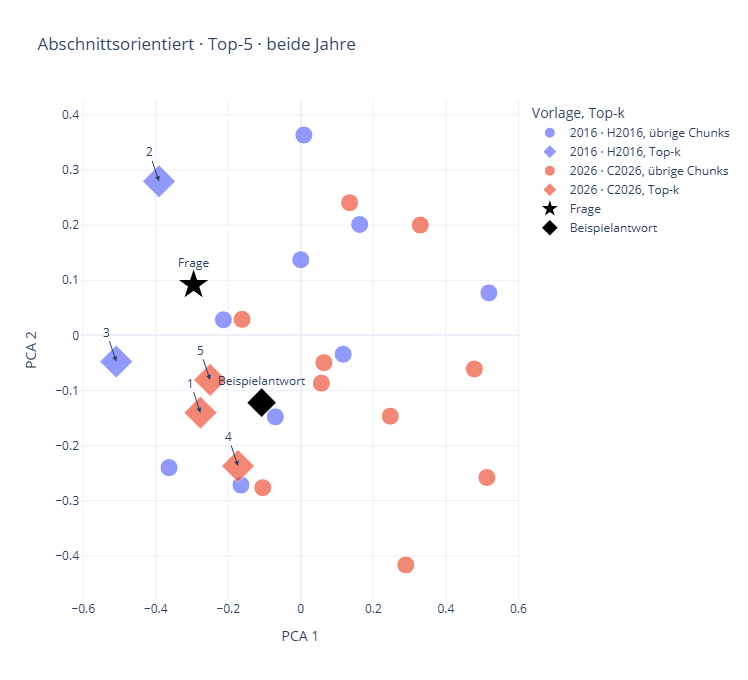

In [4]:
plot_data = selection.copy()
plot_data["Top-k"] = np.where(plot_data["item_id"].isin(top_ids), "Top-k", "übrige Chunks")
plot_data["Punktgrösse"] = np.where(plot_data["item_id"].isin(top_ids), 16, 8)
plot_data["Auszug"] = plot_data["text"].str.slice(0, 240)

fig = px.scatter(
    plot_data,
    x="pca_1",
    y="pca_2",
    color="year_label",
    symbol="Top-k",
    size="Punktgrösse",
    size_max=18,
    hover_name="item_id",
    hover_data={
        "role": True,
        "pages": True,
        "similarity": ":.3f",
        "Auszug": True,
        "pca_1": False,
        "pca_2": False,
        "Punktgrösse": False,
    },
    title=f"{plot_data['strategy_label'].iloc[0]} · Top-{TOP_K} · " + ("nur 2026" if NUR_2026 else "beide Jahre"),
    labels={"pca_1": "PCA 1", "pca_2": "PCA 2", "year_label": "Vorlage"},
)

specials = points.query("kind != 'chunk'")
for _, row in specials.iterrows():
    fig.add_trace(go.Scatter(
        x=[row["pca_1"]], y=[row["pca_2"]],
        mode="markers+text", name=row["label"], text=[row["label"]],
        textposition="top center",
        marker={"symbol": "star" if row["kind"] == "question" else "diamond", "size": 22, "color": "black"},
        hovertext=textwrap.shorten(row["text"], width=500, placeholder=" …"), hoverinfo="text",
    ))

for _, row in top.iterrows():
    fig.add_annotation(x=row["pca_1"], y=row["pca_2"], text=str(int(row["rank"])), showarrow=True, arrowhead=2)

fig.update_layout(template="plotly_white", height=680)
fig.show()

### Beobachtung A: Baseline

- Welche beiden Chunks wirken besonders nützlich?
- Welcher Treffer überrascht euch?
- Enthalten die Top-k beide Jahre? Ist das für diese Frage sinnvoll?

_Notizen …_

## 4. Strategie vergleichen

Geht zur Einstellungszelle zurück und ändert **nur** `STRATEGIE`. Führt die beiden Analysezellen erneut aus. Wiederholt dies bei Bedarf mit der dritten Strategie.

Notiert:

- einen Chunk, der neu in die Top-k kommt;
- einen Chunk, der herausfällt oder seinen Rang deutlich verändert;
- eine konkrete Chunk-Grenze, ein behaltenes Wort oder verlorenen Kontext, der den Unterschied erklären könnte.

_Vergleich …_

## 5. Jahresfilter testen

Setzt `NUR_2026 = True` und führt die Analyse erneut aus.

- Welche zeitliche Verwechslung verhindert der Filter?
- Welche Evidenz geht verloren, obwohl sie für den historischen Vergleich nötig wäre?
- Was wäre für einen Abstimmungsassistenten besser als ein starrer Jahresfilter?

_Beobachtung …_

## 6. PCA gegen den vollständigen Vektorraum prüfen

Die folgende Zelle vergleicht zwei Ranglisten:

- **Kosinus-Rang:** massgeblich für Retrieval, berechnet in 384 Dimensionen
- **PCA-Nähe:** euklidische Distanz in der zweidimensionalen Zeichnung

Eine Abweichung ist kein Fehler. Sie zeigt, welche Information bei der Projektion verloren geht.

In [5]:
question = points.query("kind == 'question'").iloc[0]
check = selection.copy()
check["pca_distance"] = np.sqrt(
    (check["pca_1"] - question["pca_1"]) ** 2
    + (check["pca_2"] - question["pca_2"]) ** 2
)
check["Kosinus-Rang"] = check["similarity"].rank(method="min", ascending=False).astype(int)
check["PCA-Nähe-Rang"] = check["pca_distance"].rank(method="min", ascending=True).astype(int)
check["Rangdifferenz"] = (check["Kosinus-Rang"] - check["PCA-Nähe-Rang"]).abs()

pca_mismatch = check.sort_values("Rangdifferenz", ascending=False).head(8)[
    ["item_id", "year", "pages", "similarity", "pca_distance", "Kosinus-Rang", "PCA-Nähe-Rang", "Rangdifferenz"]
].copy()
pca_mismatch.columns = [
    "Chunk-ID", "Jahr", "Seite", "Kosinusähnlichkeit", "PCA-Abstand",
    "Kosinus-Rang", "PCA-Nähe-Rang", "Rangdifferenz"
]
pca_mismatch[["Kosinusähnlichkeit", "PCA-Abstand"]] = pca_mismatch[["Kosinusähnlichkeit", "PCA-Abstand"]].round(3)
display(pca_mismatch.style.hide(axis="index"))

Chunk-ID,Jahr,Seite,Kosinusähnlichkeit,PCA-Abstand,Kosinus-Rang,PCA-Nähe-Rang,Rangdifferenz
H2016-P11-ABSCHNITT-02,2016,11.000000,0.592000,0.104000,10,1,9
H2016-P08-ABSCHNITT-02,2016,8.000000,0.604000,0.431000,8,16,8
H2016-P11-ABSCHNITT-01,2016,11.000000,0.612000,0.408000,7,14,7
C2026-P38-ABSCHNITT-01,2026,38.000000,0.638000,0.351000,4,10,6
C2026-P41-ABSCHNITT-02,2026,41.000000,0.504000,0.386000,17,11,6
H2016-P12-ABSCHNITT-02,2016,12.000000,0.559000,0.329000,13,8,5
H2016-P05-ABSCHNITT-02,2016,5.000000,0.555000,0.339000,14,9,5
H2016-P07-ABSCHNITT-01,2016,7.000000,0.586000,0.299000,11,7,4


### Beobachtung B: Grenze der PCA

Wählt einen Chunk mit grosser Rangdifferenz. Beschreibt in einem Satz, weshalb die zweidimensionale Karte allein zu einer falschen Einschätzung führen könnte.

_Beobachtung …_

## 7. Schlussfolgerung für einen Abstimmungsassistenten

Formuliert gemeinsam eine konkrete Designregel. Beispiele für die Form – nicht für den Inhalt:

- „Ein Treffer darf nur verwendet werden, wenn …“
- „Neben jedem Textausschnitt muss … angezeigt werden.“
- „Vor einer vergleichenden Antwort muss das System …“

**Unsere Designregel:**

_Hier ergänzen …_

---

Die schwarze Raute zeigt eine kurze Beispielantwort als weiteren Embedding-Punkt. Sie ist keine Abstimmungsempfehlung und beweist nicht, dass die Antwort vollständig oder korrekt ist.